In [35]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()

con.sql("""
    CREATE OR REPLACE TABLE sample AS
    WITH searches AS (
        SELECT DISTINCT srch_id
        FROM read_csv('data/train.csv', nullstr = 'NULL')
    ),
    sampled AS (
        SELECT srch_id
        FROM searches
        USING SAMPLE reservoir(50000 ROWS) REPEATABLE (42)
    )
    SELECT t.*
    FROM read_csv('data/train.csv', nullstr = 'NULL') AS t
    JOIN sampled USING (srch_id)
""")

con.sql("COPY sample TO 'data/sample_50k.parquet' (FORMAT parquet)")

CountBIGINT
1239782


In [36]:
con.sql("CREATE OR REPLACE VIEW s AS SELECT * FROM 'data/sample_50k.parquet'")

CountBIGINT


In [37]:
con.sql("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT srch_id) AS n_searches FROM s").df()

,n_rows,n_searches
0,1239782,50000


In [38]:
summary = con.sql("SUMMARIZE s").df()
summary[["column_name", "column_type", "min", "max", "null_percentage"]]

,column_name,column_type,min,max,null_percentage
0,srch_id,BIGINT,25,665567,0.00
1,date_time,TIMESTAMP,2012-11-01 01:41:51,2013-06-30 23:38:23,0.00
2,site_id,BIGINT,1,34,0.00
3,visitor_location_country_id,BIGINT,1,230,0.00
4,visitor_hist_starrating,DOUBLE,1.0,5.0,94.95
5,visitor_hist_adr_usd,DOUBLE,0.0,2768.93,94.92
6,prop_country_id,BIGINT,1,230,0.00
7,prop_id,BIGINT,1,140821,0.00
8,prop_starrating,BIGINT,0,5,0.00
9,prop_review_score,DOUBLE,0.0,5.0,0.14


In [39]:
con.sql("""
    SELECT
        AVG(click_bool)   AS click_rate,
        AVG(booking_bool) AS booking_rate,
        AVG(random_bool)  AS random_share
    FROM s
""").df()

,click_rate,booking_rate,random_share
0,0.044791,0.027782,0.301071


In [40]:
con.sql("""
    SELECT AVG(has_booking) AS searches_with_booking
    FROM (
        SELECT srch_id, MAX(booking_bool) AS has_booking
        FROM s
        GROUP BY srch_id
    )
""").df()

,searches_with_booking
0,0.68888


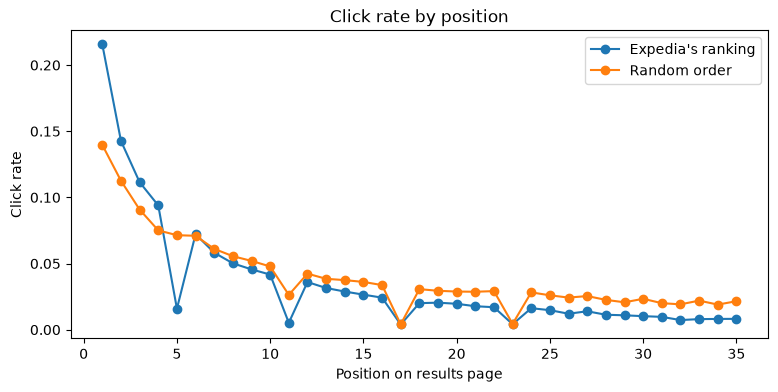

In [41]:
pos = con.sql("""
    SELECT position, random_bool,
           AVG(click_bool) AS click_rate
    FROM s
    WHERE position <= 35
    GROUP BY position, random_bool
    ORDER BY position
""").df()

fig, ax = plt.subplots(figsize=(9, 4))
for rb, grp in pos.groupby("random_bool"):
    label = "Random order" if rb == 1 else "Expedia's ranking"
    ax.plot(grp["position"], grp["click_rate"], marker="o", label=label)

ax.set_xlabel("Position on results page")
ax.set_ylabel("Click rate")
ax.set_title("Click rate by position")
ax.legend()
plt.show()

In [42]:
# reason to select position <= 35
con.sql("SELECT position, COUNT(*) AS n FROM s GROUP BY position ORDER BY position DESC").df()

,position,n
0,40,15
1,39,417
2,38,2689
3,37,9290
4,36,16832
5,35,21981
6,34,24859
7,33,26487
8,32,27975
9,31,29707


In [43]:
con.sql("""
    CREATE OR REPLACE TABLE base AS
    SELECT
        *,
        CASE
            WHEN booking_bool = 1 THEN 5
            WHEN click_bool   = 1 THEN 1
            ELSE 0
        END AS relevance
    FROM s
""")

CountBIGINT
1239782


In [44]:
con.sql("""
    SELECT relevance,
           COUNT(*) AS n,
           COUNT(*) * 1.0 / SUM(COUNT(*)) OVER () AS share
    FROM base
    GROUP BY relevance
    ORDER BY relevance
""").df()

,relevance,n,share
0,0,1184251,0.955209
1,1,21087,0.017009
2,5,34444,0.027782


In [45]:
con.sql("""
    SELECT COUNT(*) AS bookings_without_click
    FROM base
    WHERE booking_bool = 1 AND click_bool = 0
""").df()

,bookings_without_click
0,0


In [46]:
TARGET_COLS = ["click_bool", "booking_bool", "gross_bookings_usd", "relevance"]
LEAKY_COLS  = ["position"]
EVAL_ONLY   = ["random_bool"]
ID_COLS     = ["srch_id", "prop_id", "date_time", "srch_destination_id"]

EXCLUDE = TARGET_COLS + LEAKY_COLS + EVAL_ONLY + ID_COLS

In [47]:
comp_cheaper = " + ".join(
    [f"COALESCE(CAST(comp{i}_rate = 1 AS INT), 0)" for i in range(1, 9)]
)
comp_dearer = " + ".join(
    [f"COALESCE(CAST(comp{i}_rate = -1 AS INT), 0)" for i in range(1, 9)]
)
comp_known = " + ".join(
    [f"CAST(comp{i}_rate IS NOT NULL AS INT)" for i in range(1, 9)]
)

print(comp_cheaper)

COALESCE(CAST(comp1_rate = 1 AS INT), 0) + COALESCE(CAST(comp2_rate = 1 AS INT), 0) + COALESCE(CAST(comp3_rate = 1 AS INT), 0) + COALESCE(CAST(comp4_rate = 1 AS INT), 0) + COALESCE(CAST(comp5_rate = 1 AS INT), 0) + COALESCE(CAST(comp6_rate = 1 AS INT), 0) + COALESCE(CAST(comp7_rate = 1 AS INT), 0) + COALESCE(CAST(comp8_rate = 1 AS INT), 0)


In [48]:
con.sql(f"""
    CREATE OR REPLACE TABLE features AS
    WITH p AS (
        SELECT *,
            price_usd / srch_length_of_stay AS price_per_night,
            LN(price_usd + 1)               AS log_price,
            {comp_cheaper}                  AS comp_cheaper_cnt,
            {comp_dearer}                   AS comp_dearer_cnt,
            {comp_known}                    AS comp_known_cnt
        FROM base
    )
    SELECT *,
        COUNT(*) OVER w                                    AS n_props_in_search,
        PERCENT_RANK() OVER (PARTITION BY srch_id
                             ORDER BY price_usd)           AS price_pct_rank,
        price_usd / NULLIF(MEDIAN(price_usd) OVER w, 0)    AS price_vs_median,
        prop_starrating      - AVG(prop_starrating) OVER w      AS star_vs_mean,
        prop_review_score    - AVG(prop_review_score) OVER w    AS review_vs_mean,
        prop_location_score2 - AVG(prop_location_score2) OVER w AS loc2_vs_mean,
        CASE WHEN prop_log_historical_price > 0
             THEN EXP(prop_log_historical_price) - price_per_night
        END                                                AS hist_price_diff,
        ABS(visitor_hist_starrating - prop_starrating)     AS visitor_star_diff,
        ABS(visitor_hist_adr_usd - price_per_night)        AS visitor_price_diff
    FROM p
    WINDOW w AS (PARTITION BY srch_id)
""")

con.sql("COPY features TO 'data/features_50k.parquet' (FORMAT parquet)")

CountBIGINT
1239782


In [49]:
con.sql("""
    SELECT srch_id, prop_id, price_usd, price_per_night, price_pct_rank,
           price_vs_median, star_vs_mean, comp_cheaper_cnt, relevance
    FROM features
    WHERE srch_id = (SELECT MIN(srch_id) FROM features)
    ORDER BY price_usd
""").df()

,srch_id,prop_id,price_usd,price_per_night,price_pct_rank,price_vs_median,star_vs_mean,comp_cheaper_cnt,relevance
0,25,118859,27.0,27.0,0.00000,0.509434,0.090909,1,0
1,25,81772,29.0,29.0,0.03125,0.547170,0.090909,0,0
2,25,66209,32.0,32.0,0.06250,0.603774,1.090909,0,0
3,25,88629,35.0,35.0,0.09375,0.660377,-0.909091,0,0
4,25,79870,37.0,37.0,0.12500,0.698113,-0.909091,0,0
5,25,122279,38.0,38.0,0.15625,0.716981,-0.909091,0,0
6,25,126136,39.0,39.0,0.18750,0.735849,1.090909,1,0
7,25,61189,40.0,40.0,0.21875,0.754717,0.090909,0,0
8,25,23228,42.0,42.0,0.25000,0.792453,1.090909,0,5
9,25,54226,45.0,45.0,0.28125,0.849057,1.090909,0,0
